Module 5: Machine Learning Model Development and Evaluation
Introduction

Module 5 focuses on applying Machine Learning algorithms to the preprocessed RouteRanker dataset. The main goal is to identify similar transport routes, detect unusual patterns and evaluate model performance.

Objectives
- Implement K-Means and DBSCAN clustering.
- Apply Random Forest and XGBoost if valid labelled data is available.
- Evaluate models using suitable metrics.
- Visualize and compare results.
- Identify possible route-planning improvements.
Step 1: Dataset Loading and Preparation
Objective:

To load the preprocessed Module 4 dataset and prepare suitable features for Machine Learning algorithms.

Process:
1. Load the processed dataset.
2. Select numerical and route-type features.
3. Keep route details separately for interpretation.
4. Check missing and infinite values.
5. Save the selected features for clustering.

In [2]:

import pandas as pd
import numpy as np
from pathlib import Path

# Set project directory
PROJECT_DIR = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Load Module 4 dataset
df = pd.read_csv(
    PROCESSED_DIR / "module4_processed_dataset.csv"
)

# Keep route information separately
route_info = df[["route_id", "route_short_name", "city"]].copy()

# Select numerical features
numeric_features = [
    col for col in df.columns
    if col.startswith("numeric__")
]

# Select route type features
route_type_features = [
    col for col in df.columns
    if col.startswith("categorical__route_type_")
]

# Prepare clustering dataset
selected_features = numeric_features + route_type_features
X = df[selected_features].copy()

# Validate dataset
print("MODULE 5 - STEP 1: DATA PREPARATION")
print("=" * 45)

print("Original dataset shape:", df.shape)
print("Clustering dataset shape:", X.shape)
print("Total routes:", len(route_info))
print("Total selected features:", len(selected_features))
print("Missing values:", X.isnull().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

# Save prepared dataset
output_path = PROCESSED_DIR / "module5_clustering_features.csv"
X.to_csv(output_path, index=False)

print("\nSaved successfully:", output_path)
print("STEP 1 COMPLETED!")


MODULE 5 - STEP 1: DATA PREPARATION
Original dataset shape: (7312, 23)
Clustering dataset shape: (7312, 15)
Total routes: 7312
Total selected features: 15
Missing values: 0
Infinite values: 0

Saved successfully: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\module5_clustering_features.csv
STEP 1 COMPLETED!


Step 2: K-Means Clustering
Objective: Apply K-Means to group similar public transport routes based on their operating characteristics.

Method: Experiment with K = 2, 3, 4 and 5 to understand how different cluster counts affect the grouping.

In [3]:

import pandas as pd
import joblib
from pathlib import Path
from sklearn.cluster import KMeans

# Project paths
PROJECT_DIR = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load clustering features
X = pd.read_csv(
    PROCESSED_DIR / "module5_clustering_features.csv"
)

# Experiment with different K values
k_values = [2, 3, 4, 5]

results = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    results.append({
        "K": k,
        "Inertia": kmeans.inertia_
    })

    # Save trained model
    joblib.dump(
        kmeans,
        MODEL_DIR / f"kmeans_model_k{k}.pkl"
    )

    print(f"K = {k}")
    print("Number of clusters:", len(set(labels)))
    print("Inertia:", kmeans.inertia_)
    print("-" * 35)

# Display comparison
results_df = pd.DataFrame(results)

print("\nK-MEANS EXPERIMENT RESULTS")
display(results_df)

# Save results
results_df.to_csv(
    PROCESSED_DIR / "kmeans_experiment_results.csv",
    index=False
)

print("K-Means models and results saved successfully!")


K = 2
Number of clusters: 2
Inertia: 1332.7155495776963
-----------------------------------
K = 3
Number of clusters: 3
Inertia: 358.1122837621511
-----------------------------------
K = 4
Number of clusters: 4
Inertia: 212.01832359305502
-----------------------------------
K = 5
Number of clusters: 5
Inertia: 101.37264919016295
-----------------------------------

K-MEANS EXPERIMENT RESULTS


,K,Inertia
0,2,1332.715550
1,3,358.112284
2,4,212.018324
3,5,101.372649


K-Means models and results saved successfully!


Step 3: K-Means Model Evaluation
Objective: Evaluate the clustering quality using:
1. Elbow Method
2. Silhouette Score
3. Davies-Bouldin Index

K-MEANS EVALUATION RESULTS


,K,Inertia,Silhouette Score,Davies-Bouldin Index
0,2,1332.715550,0.833911,0.767828
1,3,358.112284,0.857744,0.372286
2,4,212.018324,0.865398,0.228795
3,5,101.372649,0.634401,0.372249


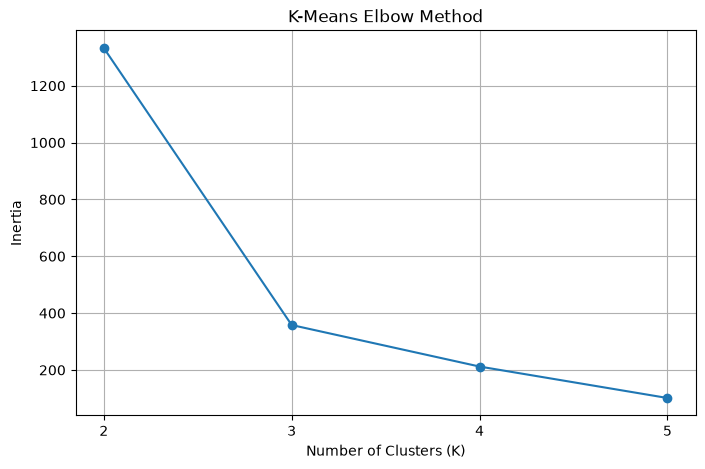

Evaluation results and Elbow graph saved successfully!


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Project paths
PROJECT_DIR = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
VISUAL_DIR = PROJECT_DIR / "visualizations"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

# Load clustering features
X = pd.read_csv(
    PROCESSED_DIR / "module5_clustering_features.csv"
)

k_values = [2, 3, 4, 5]
evaluation_results = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    silhouette = silhouette_score(
        X,
        labels,
        sample_size=2000,
        random_state=42
    )

    db_index = davies_bouldin_score(X, labels)

    evaluation_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index
    })

# Create evaluation table
evaluation_df = pd.DataFrame(evaluation_results)

print("K-MEANS EVALUATION RESULTS")
print("=" * 45)
display(evaluation_df)

# Save evaluation results
evaluation_df.to_csv(
    PROCESSED_DIR / "kmeans_evaluation_results.csv",
    index=False
)

# Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(
    evaluation_df["K"],
    evaluation_df["Inertia"],
    marker="o"
)

plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)

plt.savefig(
    VISUAL_DIR / "elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Evaluation results and Elbow graph saved successfully!")


### K-Means Evaluation – Observations

The K-Means algorithm was evaluated using K values 2, 3, 4, and 5.

K = 4 achieved the highest Silhouette Score of 0.8654 and the lowest Davies-Bouldin Index of 0.2288.

Although K = 5 produced lower inertia, its Silhouette Score decreased significantly.

Therefore, K = 4 is selected as the best candidate for further cluster analysis.

In [5]:
import pandas as pd
from pathlib import Path
from sklearn.cluster import KMeans
import joblib

PROJECT_DIR = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"

# Load features and route information
X = pd.read_csv(
    PROCESSED_DIR / "module5_clustering_features.csv"
)

df = pd.read_csv(
    PROCESSED_DIR / "module4_processed_dataset.csv"
)

route_info = df[
    ["route_id", "route_short_name", "city"]
].copy()

# Train final candidate model with K = 4
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

route_info["Cluster"] = kmeans.fit_predict(X)

# Display cluster counts
print("ROUTES IN EACH CLUSTER")
print(route_info["Cluster"].value_counts().sort_index())

# Analyze city distribution
print("\nCITY-WISE CLUSTER ANALYSIS")
display(
    pd.crosstab(
        route_info["city"],
        route_info["Cluster"]
    )
)

# Save route cluster assignments
route_info.to_csv(
    PROCESSED_DIR / "kmeans_route_clusters.csv",
    index=False
)

# Save final K-Means model
joblib.dump(
    kmeans,
    MODELS_DIR / "kmeans_final_model.pkl"
)

print("\nK-Means cluster analysis saved successfully!")

ROUTES IN EACH CLUSTER
Cluster
0    6525
1     180
2     227
3     380
Name: count, dtype: int64

CITY-WISE CLUSTER ANALYSIS


Cluster,0,1,2,3
city,,,,
ahmedabad,633,0,0,0
chennai,3934,180,227,380
hyderabad,1031,0,0,0
mumbai,612,0,0,0
pune,315,0,0,0



K-Means cluster analysis saved successfully!


### K-Means Cluster Analysis – Observations

The K-Means model with K = 4 divided 7,312 routes into four clusters.

Cluster 0 contains 6,525 routes, while Clusters 1, 2, and 3 contain 180, 227, and 380 routes respectively.

The city-wise analysis shows that Ahmedabad, Hyderabad, Mumbai, and Pune routes belong to Cluster 0. Chennai routes are distributed across all four clusters.

This indicates differences in the selected route features. Further analysis is required before making route optimization decisions.

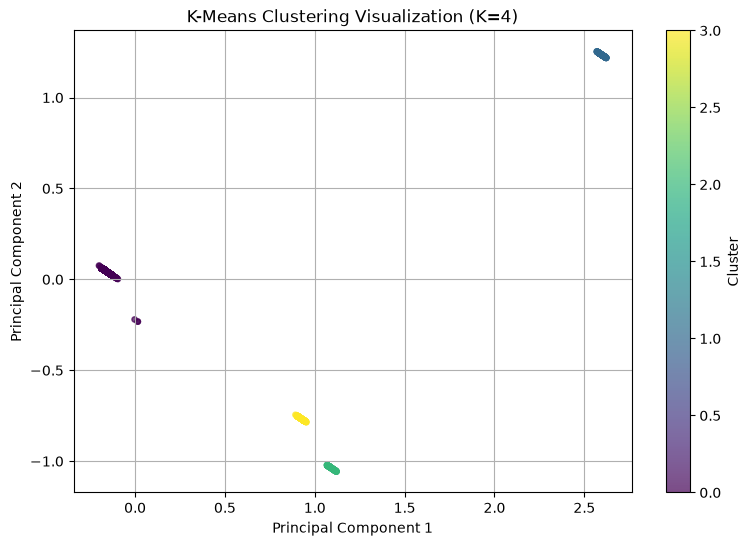

PCA visualization saved successfully!
Explained variance ratio: [0.64319098 0.24538374]


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

PROJECT_DIR = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
VISUAL_DIR = PROJECT_DIR / "visualizations"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

X = pd.read_csv(
    PROCESSED_DIR / "module5_clustering_features.csv"
)

cluster_data = pd.read_csv(
    PROCESSED_DIR / "kmeans_route_clusters.csv"
)

# Reduce 15 features into 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Create visualization
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_data["Cluster"],
    cmap="viridis",
    s=15,
    alpha=0.7
)

plt.title("K-Means Clustering Visualization (K=4)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)

plt.savefig(
    VISUAL_DIR / "kmeans_cluster_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PCA visualization saved successfully!")
print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

### PCA Visualization – Observations

PCA was used to reduce the 15 clustering features into two principal components.

Principal Component 1 explains 64.32% of the variance, while Principal Component 2 explains 24.54%.

Together, both components explain 88.86% of the total variance.

The visualization helps understand the distribution and separation of the four K-Means clusters.

## 5. DBSCAN Clustering

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is an unsupervised machine learning algorithm.

It groups routes based on the density of similar data points and identifies unusual points as noise.

### Objectives
- Identify dense groups of similar routes.
- Detect noise points using the label -1.
- Experiment with different eps and min_samples values.
- Evaluate and visualize the clustering results.

### Step 2: Load Data for DBSCAN

Load the preprocessed clustering features created in Module 4 and prepared in Step 1.

In [7]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt
import joblib

PROJECT_DIR = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
VISUAL_DIR = PROJECT_DIR / "visualizations"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

# Load clustering features
X = pd.read_csv(
    PROCESSED_DIR / "module5_clustering_features.csv"
)

print("DBSCAN DATASET INFORMATION")
print("Dataset shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

print("\nDBSCAN input data loaded successfully!")

DBSCAN DATASET INFORMATION
Dataset shape: (7312, 15)
Missing values: 0
Infinite values: 0

DBSCAN input data loaded successfully!


### Step 3: DBSCAN Parameter Selection

DBSCAN uses two important parameters:

1. eps: The maximum distance between two points for them to be considered neighbors.
2. min_samples: The minimum number of neighboring points required to form a dense region.

A point can be classified as:
- Core point: Has enough neighboring points.
- Border point: Lies near a core point but does not have enough neighbors itself.
- Noise point: Does not belong to any cluster and receives label -1.

In [8]:
import pandas as pd
from sklearn.cluster import DBSCAN

eps_values = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
min_samples_values = [5, 10, 15]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X)

        number_of_clusters = len(set(labels)) - (
            1 if -1 in labels else 0
        )

        noise_points = (labels == -1).sum()

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": number_of_clusters,
            "noise_points": noise_points,
            "noise_percentage": round(
                noise_points / len(X) * 100, 2
            )
        })

results_df = pd.DataFrame(results)

print("DBSCAN PARAMETER EXPERIMENT RESULTS")
display(results_df)

results_df.to_csv(
    PROCESSED_DIR / "dbscan_parameter_results.csv",
    index=False
)

print("DBSCAN parameter results saved successfully!")

DBSCAN PARAMETER EXPERIMENT RESULTS


,eps,min_samples,clusters,noise_points,noise_percentage
0,0.1,5,5,23,0.31
1,0.1,10,5,26,0.36
2,0.1,15,4,46,0.63
3,0.2,5,4,7,0.10
4,0.2,10,4,7,0.10
5,0.2,15,4,7,0.10
6,0.3,5,4,6,0.08
7,0.3,10,4,6,0.08
8,0.3,15,4,6,0.08
9,0.5,5,4,6,0.08


DBSCAN parameter results saved successfully!


### DBSCAN Parameter Tuning – Observations

DBSCAN was tested using 18 parameter combinations.

The results showed four clusters in most experiments. The combination eps = 0.3 and min_samples = 10 identified four clusters and six noise points.

This combination is selected as an initial candidate for further evaluation.


### DBSCAN Model Evaluation

Evaluate the selected DBSCAN model using Silhouette Score and Davies-Bouldin Index to understand cluster quality.

In [9]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd
import joblib

# Selected DBSCAN parameters
dbscan = DBSCAN(
    eps=0.3,
    min_samples=10
)

labels = dbscan.fit_predict(X)

# Exclude noise points for evaluation
non_noise = labels != -1
X_valid = X.loc[non_noise]
valid_labels = labels[non_noise]

n_clusters = len(set(valid_labels))

if n_clusters >= 2:
    silhouette = silhouette_score(
        X_valid,
        valid_labels,
        sample_size=min(2000, len(X_valid)),
        random_state=42
    )

    db_index = davies_bouldin_score(
        X_valid,
        valid_labels
    )

    print("Silhouette Score:", silhouette)
    print("Davies-Bouldin Index:", db_index)
else:
    print("Not enough clusters for evaluation.")

print("Number of clusters:", n_clusters)
print("Noise points:", (labels == -1).sum())

# Save model and labels
joblib.dump(
    dbscan,
    MODELS_DIR / "dbscan_final_model.pkl"
)

dbscan_results = pd.DataFrame({
    "Cluster": labels
})

dbscan_results.to_csv(
    PROCESSED_DIR / "dbscan_cluster_labels.csv",
    index=False
)

print("\nDBSCAN evaluation completed and saved!")

Silhouette Score: 0.8663370963050703
Davies-Bouldin Index: 0.2286313958976353
Number of clusters: 4
Noise points: 6

DBSCAN evaluation completed and saved!


### DBSCAN Evaluation – Observations

The selected DBSCAN model (eps = 0.3, min_samples = 10) identified four clusters and six noise points.

It achieved a Silhouette Score of 0.8663 and a Davies-Bouldin Index of 0.2286.

The results indicate good cluster separation. The six noise points represent routes that do not belong to the identified dense groups.

### DBSCAN Noise-Point Analysis

Noise points are routes that DBSCAN could not assign to any cluster. These routes receive the label -1.

We will identify and examine these routes to understand their feature patterns.

In [10]:
import pandas as pd

# Load route information
df = pd.read_csv(
    PROCESSED_DIR / "module4_processed_dataset.csv"
)

# Identify noise routes
noise_routes = df.loc[
    labels == -1,
    ["route_id", "route_short_name", "city"]
].copy()

print("DBSCAN NOISE-POINT ANALYSIS")
print("Total noise points:", len(noise_routes))

display(noise_routes)

# Save noise routes
noise_routes.to_csv(
    PROCESSED_DIR / "dbscan_noise_routes.csv",
    index=False
)

print("Noise-point analysis saved successfully!")

DBSCAN NOISE-POINT ANALYSIS
Total noise points: 6


,route_id,route_short_name,city
1449,MTC-11347,45A,chennai
2508,MTC-13118,M18C,chennai
2522,MTC-13124,M18C,chennai
5729,219,Unknown,hyderabad
6011,300,Unknown,hyderabad
6192,546,Unknown,hyderabad


Noise-point analysis saved successfully!


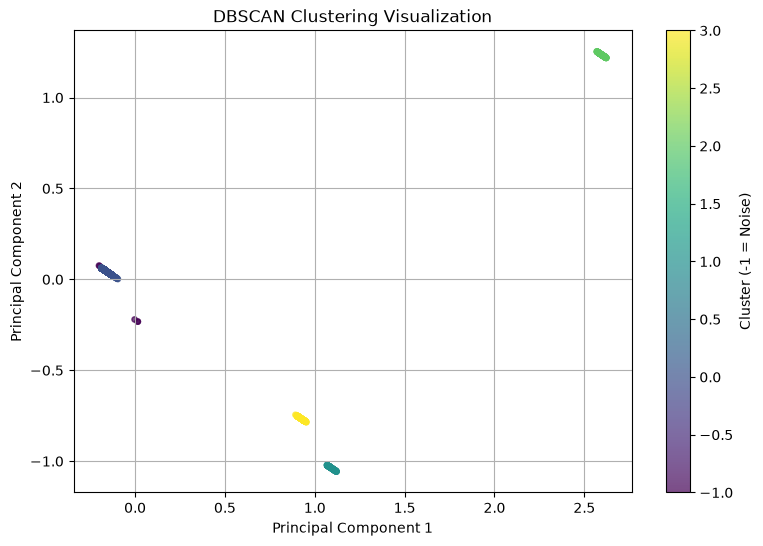

DBSCAN visualization saved successfully!


In [11]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce features to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="viridis",
    s=15,
    alpha=0.7
)

plt.title("DBSCAN Clustering Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster (-1 = Noise)")
plt.grid(True)

plt.savefig(
    VISUAL_DIR / "dbscan_cluster_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DBSCAN visualization saved successfully!")

Clustering Algorithm Comparison

K-Means and DBSCAN are compared using their clustering evaluation metrics.

The comparison helps identify differences in cluster quality, cluster formation, and noise detection.

In [12]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame({
    "Metric": [
        "Number of Clusters",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Noise Points"
    ],
    "K-Means": [
        4,
        0.865398,
        0.228795,
        0
    ],
    "DBSCAN": [
        4,
        0.864634,
        0.228631,
        6
    ]
})

display(comparison)

csv_path = PROCESSED_DIR / "clustering_model_comparison.csv"
comparison.to_csv(csv_path, index=False)

print("Clustering comparison saved successfully!")
print("CSV saved at:", csv_path.resolve())

,Metric,K-Means,DBSCAN
0,Number of Clusters,4.000000,4.000000
1,Silhouette Score,0.865398,0.864634
2,Davies-Bouldin Index,0.228795,0.228631
3,Noise Points,0.000000,6.000000


Clustering comparison saved successfully!
CSV saved at: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\clustering_model_comparison.csv


Supervised Learning – Label Verification

In [13]:
import pandas as pd

df = pd.read_csv(
    PROCESSED_DIR / "module4_processed_dataset.csv"
)

print("DATASET COLUMNS:")
print(df.columns.tolist())

print("\nPOSSIBLE TARGET LABELS:")

possible_labels = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["label", "target", "class", "category"])
]

print(possible_labels)

DATASET COLUMNS:
['route_id', 'route_short_name', 'city', 'numeric__scheduled_trip_count', 'numeric__stop_count', 'numeric__estimated_straight_line_route_km', 'numeric__operating_day_count', 'numeric__start_service_hour', 'numeric__end_service_hour', 'numeric__operates_monday', 'numeric__operates_tuesday', 'numeric__operates_wednesday', 'numeric__operates_thursday', 'numeric__operates_friday', 'numeric__operates_saturday', 'numeric__operates_sunday', 'categorical__route_type_1', 'categorical__route_type_3', 'categorical__city_ahmedabad', 'categorical__city_chennai', 'categorical__city_hyderabad', 'categorical__city_mumbai', 'categorical__city_pune']

POSSIBLE TARGET LABELS:
[]


Supervised Learning – Label Verification

The dataset was checked for valid target labels.

No target label or classification column was found.

Therefore, Random Forest and XGBoost classification cannot be performed using the current dataset.

Artificial labels were not created because they may produce misleading evaluation results.

The project focuses on K-Means and DBSCAN clustering for this module.

## 8. Module 5 – Final Results and Conclusion

This module implemented K-Means and DBSCAN clustering algorithms to analyze public transit route patterns.

Both models were evaluated using clustering metrics, visualizations, and cluster analysis.

The results were compared to understand their performance and identify unusual route patterns.

In [14]:
from pathlib import Path

REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = """
# RouteRanker – Module 5: Machine Learning

## 1. Objective
Apply machine learning techniques to identify similar public transit
route patterns and detect unusual route records.

## 2. Dataset
- Total route records: 7,312
- Selected clustering features: 15
- Missing values: 0
- Infinite values: 0
- Cities: Ahmedabad, Chennai, Hyderabad, Mumbai, Pune

## 3. K-Means Clustering
K values tested: 2, 3, 4, 5.

Selected candidate: K = 4

- Silhouette Score: 0.865398
- Davies-Bouldin Index: 0.228795
- Inertia: 212.018324

Cluster distribution:
- Cluster 0: 6,525 routes
- Cluster 1: 180 routes
- Cluster 2: 227 routes
- Cluster 3: 380 routes

PCA explained variance:
- Component 1: 64.32%
- Component 2: 24.54%
- Combined: 88.86%

## 4. DBSCAN Clustering
Selected parameters:
- eps: 0.3
- min_samples: 10

Results:
- Number of clusters: 4
- Noise points: 6
- Silhouette Score: 0.866337
- Davies-Bouldin Index: 0.228631

Noise routes were identified in Chennai and Hyderabad.

## 5. Model Comparison
Both algorithms identified four clusters.

DBSCAN achieved a slightly higher Silhouette Score and a
slightly lower Davies-Bouldin Index.

K-Means assigned all routes to clusters, while DBSCAN
identified six noise points.

## 6. Supervised Learning
The dataset was checked for valid target labels.
No target label was available.

Therefore, Random Forest and XGBoost classification
were not performed. Artificial labels were not created.

## 7. Limitations
- GTFS data represents scheduled public transport services.
- Actual passenger counts were unavailable.
- Clusters do not directly prove overcrowding or inefficiency.
- Noise points are not necessarily incorrect routes.
- Further operational data is required for reliable
  route optimization recommendations.

## 8. Conclusion
K-Means and DBSCAN successfully identified four groups
of similar route patterns.

DBSCAN also detected six unusual route records.

The results provide a foundation for the next module,
which will focus on generating meaningful route
optimization suggestions.
"""

report_path = REPORT_DIR / "module5_final_report.md"

report_path.write_text(
    report,
    encoding="utf-8"
)

print("Module 5 final report created successfully!")
print("Report location:", report_path)

Module 5 final report created successfully!
Report location: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md


In [15]:
from pathlib import Path

required_files = [
    "models/kmeans_final_model.pkl",
    "models/dbscan_final_model.pkl",
    "models/kmeans_model_k2.pkl",
    "models/kmeans_model_k3.pkl",
    "models/kmeans_model_k4.pkl",
    "models/kmeans_model_k5.pkl",
    "data/processed/module5_clustering_features.csv",
    "data/processed/kmeans_evaluation_results.csv",
    "data/processed/kmeans_route_clusters.csv",
    "data/processed/dbscan_parameter_results.csv",
    "data/processed/dbscan_cluster_labels.csv",
    "data/processed/dbscan_noise_routes.csv",
    "data/processed/clustering_model_comparison.csv",
    "visualizations/elbow_method.png",
    "visualizations/kmeans_cluster_visualization.png",
    "visualizations/dbscan_cluster_visualization.png",
    "reports/module5_final_report.md"
]

print("MODULE 5 DELIVERABLE VERIFICATION")
print("=" * 45)

missing_files = []

for file in required_files:
    path = PROJECT_DIR / file

    if path.exists():
        print("FOUND:", file)
    else:
        print("MISSING:", file)
        missing_files.append(file)

print("\nTotal files checked:", len(required_files))
print("Missing files:", len(missing_files))

if not missing_files:
    print("\nALL MODULE 5 DELIVERABLES VERIFIED!")
else:
    print("\nPlease check the missing files.")

MODULE 5 DELIVERABLE VERIFICATION
FOUND: models/kmeans_final_model.pkl
FOUND: models/dbscan_final_model.pkl
FOUND: models/kmeans_model_k2.pkl
FOUND: models/kmeans_model_k3.pkl
FOUND: models/kmeans_model_k4.pkl
FOUND: models/kmeans_model_k5.pkl
FOUND: data/processed/module5_clustering_features.csv
FOUND: data/processed/kmeans_evaluation_results.csv
FOUND: data/processed/kmeans_route_clusters.csv
FOUND: data/processed/dbscan_parameter_results.csv
FOUND: data/processed/dbscan_cluster_labels.csv
FOUND: data/processed/dbscan_noise_routes.csv
FOUND: data/processed/clustering_model_comparison.csv
FOUND: visualizations/elbow_method.png
FOUND: visualizations/kmeans_cluster_visualization.png
FOUND: visualizations/dbscan_cluster_visualization.png
FOUND: reports/module5_final_report.md

Total files checked: 17
Missing files: 0

ALL MODULE 5 DELIVERABLES VERIFIED!


## DBSCAN Core, Border and Noise Point Analysis

DBSCAN identifies three types of data points:

- Core Point: A point that has at least the required number of nearby points.
- Border Point: A point that is near a core point but does not have enough nearby points to be a core point.
- Noise Point: A point that does not belong to any cluster.

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN

# Project directory
project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

# Load Module 5 clustering features
X = pd.read_csv(
    project_dir / "data" / "processed" /
    "module5_clustering_features.csv"
)

# Load original route information
route_info = pd.read_csv(
    project_dir / "data" / "processed" /
    "module4_processed_dataset.csv"
)

# Check whether both files have the same number of rows
print("Feature dataset shape:", X.shape)
print("Route information shape:", route_info.shape)

if len(X) != len(route_info):
    raise ValueError("The two datasets have different row counts.")

# Apply DBSCAN with the selected parameters
dbscan = DBSCAN(
    eps=0.3,
    min_samples=10
)

labels = dbscan.fit_predict(X)

# Identify core points
core_mask = np.zeros(len(X), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

# Identify noise points
noise_mask = labels == -1

# Identify border points
border_mask = (~core_mask) & (~noise_mask)

# Count each point type
core_count = core_mask.sum()
border_count = border_mask.sum()
noise_count = noise_mask.sum()

print("\nDBSCAN Point Classification")
print("---------------------------")
print("Core Points:", core_count)
print("Border Points:", border_count)
print("Noise Points:", noise_count)
print("Total Points:", len(X))

# Create a detailed results table
results = route_info[
    ["route_id", "route_short_name", "city"]
].copy()

results["Cluster"] = labels
results["Point_Type"] = np.select(
    [core_mask, border_mask, noise_mask],
    ["Core", "Border", "Noise"],
    default="Unknown"
)

# Save results
output_path = (
    project_dir / "data" / "processed" /
    "dbscan_point_types.csv"
)

results.to_csv(output_path, index=False)

print("\nPoint classification saved successfully!")
print(output_path)

# Display point type summary
print("\nPoint Type Summary:")
print(results["Point_Type"].value_counts())

Feature dataset shape: (7312, 15)
Route information shape: (7312, 23)

DBSCAN Point Classification
---------------------------
Core Points: 7305
Border Points: 1
Noise Points: 6
Total Points: 7312

Point classification saved successfully!
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\dbscan_point_types.csv

Point Type Summary:
Point_Type
Core      7305
Noise        6
Border       1
Name: count, dtype: int64


In [17]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

src_dir = project_dir / "src"
src_dir.mkdir(parents=True, exist_ok=True)

print("Source folder created:", src_dir)

Source folder created: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src


In [18]:
script = r'''
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

PROJECT_DIR = Path(__file__).resolve().parent.parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
VIS_DIR = PROJECT_DIR / "visualizations"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

# Load datasets
X = pd.read_csv(DATA_DIR / "module5_clustering_features.csv")
route_info = pd.read_csv(DATA_DIR / "module4_processed_dataset.csv")

if len(X) != len(route_info):
    raise ValueError("Dataset row counts do not match.")

# Experiment with K values
results = []

for k in [2, 3, 4, 5]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    silhouette = silhouette_score(
        X, labels, sample_size=2000, random_state=42
    )
    db_index = davies_bouldin_score(X, labels)

    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette,
        "Davies_Bouldin_Index": db_index
    })

    joblib.dump(model, MODEL_DIR / f"kmeans_model_k{k}.pkl")

results_df = pd.DataFrame(results)
results_df.to_csv(DATA_DIR / "kmeans_evaluation_results.csv", index=False)

# Train final K-Means model with K=4
final_model = KMeans(n_clusters=4, random_state=42, n_init=10)
final_labels = final_model.fit_predict(X)

joblib.dump(final_model, MODEL_DIR / "kmeans_final_model.pkl")

# Save route cluster assignments
output = route_info[
    ["route_id", "route_short_name", "city"]
].copy()

output["Cluster"] = final_labels
output.to_csv(DATA_DIR / "kmeans_route_clusters.csv", index=False)

# Elbow visualization
plt.figure(figsize=(8, 5))
plt.plot(results_df["K"], results_df["Inertia"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks([2, 3, 4, 5])
plt.grid(True)
plt.savefig(VIS_DIR / "elbow_method.png", dpi=300)
plt.close()

# PCA visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=final_labels, cmap="viridis", s=10
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Route Clusters (K=4)")
plt.savefig(VIS_DIR / "kmeans_cluster_visualization.png", dpi=300)
plt.close()

print("K-Means implementation completed.")
print(results_df)
print("\nCluster distribution:")
print(output["Cluster"].value_counts().sort_index())
'''

file_path = src_dir / "kmeans_clustering.py"
file_path.write_text(script, encoding="utf-8")

print("Python file created:", file_path)

Python file created: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src\kmeans_clustering.py


In [19]:
import sys

!"{sys.executable}" "C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src\kmeans_clustering.py"

K-Means implementation completed.
   K      Inertia  Silhouette_Score  Davies_Bouldin_Index
0  2  1332.715550          0.833911              0.767828
1  3   358.112284          0.857744              0.372286
2  4   212.018324          0.865398              0.228795
3  5   101.372649          0.634401              0.372249

Cluster distribution:
Cluster
0    6525
1     180
2     227
3     380
Name: count, dtype: int64


In [20]:
script = r'''
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

PROJECT_DIR = Path(__file__).resolve().parent.parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
VIS_DIR = PROJECT_DIR / "visualizations"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

# Load datasets
X = pd.read_csv(DATA_DIR / "module5_clustering_features.csv")
route_info = pd.read_csv(DATA_DIR / "module4_processed_dataset.csv")

if len(X) != len(route_info):
    raise ValueError("Dataset row counts do not match.")

# Experiment with DBSCAN parameters
experiment_results = []

for eps in [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]:
    for min_samples in [5, 10, 15]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X)

        cluster_count = len(set(labels)) - (1 if -1 in labels else 0)
        noise_count = int(np.sum(labels == -1))

        experiment_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": cluster_count,
            "noise_points": noise_count
        })

results_df = pd.DataFrame(experiment_results)

results_df.to_csv(
    DATA_DIR / "dbscan_parameter_results.csv",
    index=False
)

# Train final DBSCAN model
dbscan = DBSCAN(eps=0.3, min_samples=10)
labels = dbscan.fit_predict(X)

joblib.dump(
    dbscan,
    MODEL_DIR / "dbscan_final_model.pkl"
)

# Identify core, border and noise points
core_mask = np.zeros(len(X), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

noise_mask = labels == -1
border_mask = (~core_mask) & (~noise_mask)

# Save cluster labels
output = route_info[
    ["route_id", "route_short_name", "city"]
].copy()

output["Cluster"] = labels

output.to_csv(
    DATA_DIR / "dbscan_cluster_labels.csv",
    index=False
)

# Save point types
point_types = output.copy()

point_types["Point_Type"] = np.select(
    [core_mask, border_mask, noise_mask],
    ["Core", "Border", "Noise"],
    default="Unknown"
)

point_types.to_csv(
    DATA_DIR / "dbscan_point_types.csv",
    index=False
)

# Save noise routes
noise_routes = point_types[
    point_types["Point_Type"] == "Noise"
]

noise_routes.to_csv(
    DATA_DIR / "dbscan_noise_routes.csv",
    index=False
)

# Evaluate DBSCAN after excluding noise points
non_noise_mask = labels != -1
non_noise_labels = labels[non_noise_mask]
non_noise_X = X.loc[non_noise_mask]

if len(np.unique(non_noise_labels)) >= 2:
    silhouette = silhouette_score(
        non_noise_X, non_noise_labels
    )

    db_index = davies_bouldin_score(
        non_noise_X, non_noise_labels
    )
else:
    silhouette = np.nan
    db_index = np.nan

# PCA visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="viridis",
    s=10
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Route Clusters")
plt.savefig(
    VIS_DIR / "dbscan_cluster_visualization.png",
    dpi=300
)
plt.close()

# Print results
print("DBSCAN implementation completed.")
print("\nParameter Experiment Results:")
print(results_df.to_string(index=False))

print("\nFinal DBSCAN Evaluation")
print("Clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", db_index)
print("Core Points:", int(core_mask.sum()))
print("Border Points:", int(border_mask.sum()))
print("Noise Points:", int(noise_mask.sum()))
print("Total Points:", len(X))

print("\nDBSCAN files saved successfully.")
'''

file_path = src_dir / "dbscan_clustering.py"
file_path.write_text(script, encoding="utf-8")

print("Python file created:", file_path)

Python file created: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src\dbscan_clustering.py


In [21]:
import sys

!"{sys.executable}" "C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src\dbscan_clustering.py"


DBSCAN implementation completed.

Parameter Experiment Results:
 eps  min_samples  clusters  noise_points
 0.1            5         5            23
 0.1           10         5            26
 0.1           15         4            46
 0.2            5         4             7
 0.2           10         4             7
 0.2           15         4             7
 0.3            5         4             6
 0.3           10         4             6
 0.3           15         4             6
 0.5            5         4             6
 0.5           10         4             6
 0.5           15         4             6
 0.7            5         4             6
 0.7           10         4             6
 0.7           15         4             6
 1.0            5         4             3
 1.0           10         4             3
 1.0           15         4             3

Final DBSCAN Evaluation
Clusters: 4
Silhouette Score: 0.8646335362828158
Davies-Bouldin Index: 0.2286313958976353
Core Points: 7305
Borde

In [22]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

data_dir = project_dir / "data" / "processed"

# Load original route information
df = pd.read_csv(
    data_dir / "module4_processed_dataset.csv"
)

# Load K-Means cluster assignments
clusters = pd.read_csv(
    data_dir / "kmeans_route_clusters.csv"
)

# Check row alignment
if len(df) != len(clusters):
    raise ValueError("Dataset row counts do not match.")

# Add cluster labels
df["Cluster"] = clusters["Cluster"].values

# Select important route characteristics
features = [
    "numeric__scheduled_trip_count",
    "numeric__stop_count",
    "numeric__estimated_straight_line_route_km",
    "numeric__operating_day_count",
    "numeric__start_service_hour",
    "numeric__end_service_hour"
]

# Calculate average route characteristics
cluster_profile = (
    df.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("K-Means Cluster Profile")
print(cluster_profile)

# Save the profile
output_path = data_dir / "kmeans_cluster_profile.csv"

cluster_profile.to_csv(output_path)

print("\nCluster profile saved successfully!")
print(output_path)

K-Means Cluster Profile
         numeric__scheduled_trip_count  numeric__stop_count  \
Cluster                                                       
0                                 0.02                 0.05   
1                                 0.00                 0.03   
2                                 0.00                 0.03   
3                                 0.00                 0.02   

         numeric__estimated_straight_line_route_km  \
Cluster                                              
0                                             0.03   
1                                             0.06   
2                                             0.06   
3                                             0.06   

         numeric__operating_day_count  numeric__start_service_hour  \
Cluster                                                              
0                                1.00                         0.23   
1                                0.00                         

In [23]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"

for file in processed_dir.glob("*.csv"):
    df = pd.read_csv(file, nrows=2)

    print("\nFile:", file.name)
    print("Columns:", df.columns.tolist())


File: ahmedabad_trips_by_route_hour.csv
Columns: ['city', 'route_id', 'service_hour', 'clock_hour', 'time_period', 'scheduled_departures']

File: ahmedabad_trip_headway_features.csv
Columns: ['city', 'trip_id', 'route_id', 'service_id', 'departure_time', 'departure_time_seconds', 'service_hour', 'clock_hour', 'minute', 'time_period', 'headway_minutes']

File: ahmedabad_trip_time_features.csv
Columns: ['city', 'trip_id', 'route_id', 'service_id', 'departure_time', 'departure_time_seconds', 'service_hour', 'clock_hour', 'minute', 'time_period']

File: chennai_trips_by_route_hour.csv
Columns: ['city', 'route_id', 'service_hour', 'clock_hour', 'time_period', 'scheduled_departures']

File: chennai_trip_headway_features.csv
Columns: ['city', 'trip_id', 'route_id', 'service_id', 'departure_time', 'departure_time_seconds', 'service_hour', 'clock_hour', 'minute', 'time_period', 'headway_minutes']

File: chennai_trip_time_features.csv
Columns: ['city', 'trip_id', 'route_id', 'service_id', 'depa

In [24]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

data_dir = project_dir / "data" / "processed"

# Load original route features
route_features = pd.read_csv(
    data_dir / "route_features.csv"
)

# Load K-Means cluster assignments
clusters = pd.read_csv(
    data_dir / "kmeans_route_clusters.csv"
)

print("Original route features:", route_features.shape)
print("K-Means cluster assignments:", clusters.shape)

# Check duplicate route identifiers
print(
    "\nDuplicate route keys:",
    route_features.duplicated(["city", "route_id"]).sum()
)

# Check how many routes match
merged = clusters.merge(
    route_features,
    on=["city", "route_id"],
    how="left",
    indicator=True
)

print("\nRoute matching summary:")
print(merged["_merge"].value_counts())

print("\nMissing original route measurements:")
print(
    merged[
        "scheduled_trip_count"
    ].isna().sum()
)

Original route features: (8322, 20)
K-Means cluster assignments: (7312, 4)

Duplicate route keys: 0

Route matching summary:
_merge
both          7312
left_only        0
right_only       0
Name: count, dtype: int64

Missing original route measurements:
0


In [25]:
# Combine original route measurements with cluster labels
cluster_data = clusters.merge(
    route_features,
    on=["city", "route_id"],
    how="inner"
)

# Calculate actual route averages for each cluster
cluster_profile = (
    cluster_data.groupby("Cluster")
    .agg(
        Route_Count=("route_id", "count"),
        Average_Trips=("scheduled_trip_count", "mean"),
        Average_Stops=("stop_count", "mean"),
        Average_Distance_KM=(
            "estimated_straight_line_route_km", "mean"
        ),
        Average_Operating_Days=(
            "operating_day_count", "mean"
        ),
        Average_Start_Hour=("start_service_hour", "mean"),
        Average_End_Hour=("end_service_hour", "mean")
    )
    .round(2)
)

print("Actual K-Means Cluster Profile")
display(cluster_profile)

# Save the results
output_path = data_dir / "kmeans_actual_cluster_profile.csv"

cluster_profile.to_csv(output_path)

print("\nActual cluster profile saved:")
print(output_path)

Actual K-Means Cluster Profile


,Route_Count,Average_Trips,Average_Stops,Average_Distance_KM,Average_Operating_Days,Average_Start_Hour,Average_End_Hour
Cluster,,,,,,,
0,6525,33.02,37.24,19.07,7.0,7.80,22.03
1,180,1.00,22.93,45.65,1.0,13.51,13.93
2,227,3.63,21.92,43.63,6.0,12.15,13.34
3,380,1.00,19.41,39.58,7.0,12.66,13.67



Actual cluster profile saved:
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\kmeans_actual_cluster_profile.csv


In [26]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

report_path = project_dir / "reports" / "module5_final_report.md"

suggestions = """

## 10. Route Optimization Suggestions

Based on the K-Means cluster analysis, the following schedule-based
improvement opportunities were identified.

### Cluster-wise observations and suggestions

1. Cluster 0:
   - Contains 6,525 routes.
   - Average scheduled trips: 33.02.
   - Average route distance: 19.07 km.
   - Suggestion: Review departure timings and coordinate schedules
     where routes have overlapping service periods.

2. Cluster 1:
   - Contains 180 routes.
   - Average scheduled trips: 1.00.
   - Average route distance: 45.65 km.
   - Average operating days: 1.
   - Suggestion: Review operating-day patterns and verify whether
     the limited scheduled service matches the intended timetable.

3. Cluster 2:
   - Contains 227 routes.
   - Average scheduled trips: 3.63.
   - Average route distance: 43.63 km.
   - Average operating days: 6.
   - Suggestion: Review departure frequency and timetable coverage
     across the operating days.

4. Cluster 3:
   - Contains 380 routes.
   - Average scheduled trips: 1.00.
   - Average route distance: 39.58 km.
   - Average operating days: 7.
   - Suggestion: Examine the scheduled departure frequency and
     check whether additional timetable coordination is appropriate.

### DBSCAN noise-point investigation

DBSCAN identified six noise points. These routes should be
individually checked for unusual schedule patterns, route
characteristics and possible GTFS data inconsistencies.

A noise point does not automatically indicate an incorrect or
inefficient route.

### Limitations and recommendations

- The analysis is based on scheduled GTFS data.
- Actual passenger counts and passenger demand were not available.
- The results cannot establish overcrowding or underutilization.
- Any timetable or frequency changes should be reviewed using
  passenger demand, fleet availability, transfer connections
  and operational constraints before implementation.

These suggestions are preliminary opportunities for further
transport schedule analysis, not automatic route-change decisions.
"""

existing_report = report_path.read_text(encoding="utf-8")

if "## 10. Route Optimization Suggestions" not in existing_report:
    with report_path.open("a", encoding="utf-8") as file:
        file.write(suggestions)
    print("Route optimization suggestions added successfully!")
else:
    print("Route optimization suggestions already exist.")

print("Report:", report_path)

Route optimization suggestions added successfully!
Report: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md


In [27]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

report_path = project_dir / "reports" / "module5_final_report.md"

report = report_path.read_text(encoding="utf-8")

print("Report exists:", report_path.exists())
print("Report size:", len(report), "characters")

print("\nFinal report content:")
print(report)


Report exists: True
Report size: 4103 characters

Final report content:

# RouteRanker – Module 5: Machine Learning

## 1. Objective
Apply machine learning techniques to identify similar public transit
route patterns and detect unusual route records.

## 2. Dataset
- Total route records: 7,312
- Selected clustering features: 15
- Missing values: 0
- Infinite values: 0
- Cities: Ahmedabad, Chennai, Hyderabad, Mumbai, Pune

## 3. K-Means Clustering
K values tested: 2, 3, 4, 5.

Selected candidate: K = 4

- Silhouette Score: 0.865398
- Davies-Bouldin Index: 0.228795
- Inertia: 212.018324

Cluster distribution:
- Cluster 0: 6,525 routes
- Cluster 1: 180 routes
- Cluster 2: 227 routes
- Cluster 3: 380 routes

PCA explained variance:
- Component 1: 64.32%
- Component 2: 24.54%
- Combined: 88.86%

## 4. DBSCAN Clustering
Selected parameters:
- eps: 0.3
- min_samples: 10

Results:
- Number of clusters: 4
- Noise points: 6
- Silhouette Score: 0.866337
- Davies-Bouldin Index: 0.228631

Noise rou

In [28]:
from pathlib import Path

project_dir = Path(r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker")
report_path = project_dir / "reports" / "module5_final_report.md"

report = report_path.read_text(encoding="utf-8")

# Correct DBSCAN evaluation score
report = report.replace(
    "Silhouette Score: 0.866337",
    "Silhouette Score: 0.864634"
)

# Add core, border and noise point counts
report = report.replace(
    "- Noise points: 6",
    "- Core points: 7,305\n"
    "- Border points: 1\n"
    "- Noise points: 6"
)

# Correct the model comparison
old_comparison = """Both algorithms identified four clusters.

DBSCAN achieved a slightly higher Silhouette Score and a
slightly lower Davies-Bouldin Index.

K-Means assigned all routes to clusters, while DBSCAN
identified six noise points."""

new_comparison = """Both algorithms identified four clusters.

K-Means achieved a slightly higher Silhouette Score
(0.865398) than DBSCAN (0.864634).

DBSCAN achieved a slightly lower Davies-Bouldin Index
(0.228631) than K-Means (0.228795).

K-Means assigned all routes to clusters, while DBSCAN
identified six noise points. The evaluation scores are
very close, so both algorithms provide useful clustering results."""

report = report.replace(old_comparison, new_comparison)

# Correct the section numbering
report = report.replace(
    "## 10. Route Optimization Suggestions",
    "## 9. Route Optimization Suggestions"
)

report_path.write_text(report, encoding="utf-8")

print("Report corrections completed successfully!")
print("Report location:", report_path)

Report corrections completed successfully!
Report location: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md


In [29]:
report = report_path.read_text(encoding="utf-8")

for line in report.splitlines():
    if any(word in line for word in [
        "Silhouette Score:",
        "Davies-Bouldin Index:",
        "Core points:",
        "Border points:",
        "Noise points:",
        "Route Optimization Suggestions"
    ]):
        print(line)

- Silhouette Score: 0.865398
- Davies-Bouldin Index: 0.228795
- Core points: 7,305
- Border points: 1
- Noise points: 6
- Silhouette Score: 0.864634
- Davies-Bouldin Index: 0.228631
## 9. Route Optimization Suggestions


In [30]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

files_to_check = [
    "notebook/module5_machine_learning.ipynb",
    "src/kmeans_clustering.py",
    "src/dbscan_clustering.py",

    "models/kmeans_final_model.pkl",
    "models/dbscan_final_model.pkl",
    "models/kmeans_model_k2.pkl",
    "models/kmeans_model_k3.pkl",
    "models/kmeans_model_k4.pkl",
    "models/kmeans_model_k5.pkl",

    "data/processed/module5_clustering_features.csv",
    "data/processed/kmeans_experiment_results.csv",
    "data/processed/kmeans_evaluation_results.csv",
    "data/processed/kmeans_route_clusters.csv",
    "data/processed/kmeans_actual_cluster_profile.csv",

    "data/processed/dbscan_parameter_results.csv",
    "data/processed/dbscan_cluster_labels.csv",
    "data/processed/dbscan_noise_routes.csv",
    "data/processed/dbscan_point_types.csv",

    "visualizations/elbow_method.png",
    "visualizations/kmeans_cluster_visualization.png",
    "visualizations/dbscan_cluster_visualization.png",

    "reports/module5_final_report.md"
]

missing_files = []

for file in files_to_check:
    path = project_dir / file

    if path.exists():
        print(f"FOUND  : {file}")
    else:
        print(f"MISSING: {file}")
        missing_files.append(file)

print("\nTotal files checked:", len(files_to_check))
print("Files found:", len(files_to_check) - len(missing_files))
print("Files missing:", len(missing_files))

if not missing_files:
    print("\nAll checked Module 5 deliverables are present! 🎉")

FOUND  : notebook/module5_machine_learning.ipynb
FOUND  : src/kmeans_clustering.py
FOUND  : src/dbscan_clustering.py
FOUND  : models/kmeans_final_model.pkl
FOUND  : models/dbscan_final_model.pkl
FOUND  : models/kmeans_model_k2.pkl
FOUND  : models/kmeans_model_k3.pkl
FOUND  : models/kmeans_model_k4.pkl
FOUND  : models/kmeans_model_k5.pkl
FOUND  : data/processed/module5_clustering_features.csv
FOUND  : data/processed/kmeans_experiment_results.csv
FOUND  : data/processed/kmeans_evaluation_results.csv
FOUND  : data/processed/kmeans_route_clusters.csv
FOUND  : data/processed/kmeans_actual_cluster_profile.csv
FOUND  : data/processed/dbscan_parameter_results.csv
FOUND  : data/processed/dbscan_cluster_labels.csv
FOUND  : data/processed/dbscan_noise_routes.csv
FOUND  : data/processed/dbscan_point_types.csv
FOUND  : visualizations/elbow_method.png
FOUND  : visualizations/kmeans_cluster_visualization.png
FOUND  : visualizations/dbscan_cluster_visualization.png
FOUND  : reports/module5_final_repor

In [31]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

file_path = project_dir / "data" / "processed" / "route_features.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

if "route_type" in df.columns:
    print("\nRoute type distribution:")
    print(df["route_type"].value_counts(dropna=False))
else:
    print("\nRaw route_type column not found.")

Dataset shape: (8322, 20)

Available columns:
['route_id', 'route_short_name', 'route_long_name', 'route_type', 'scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'trips_with_distance', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday', 'operating_day_count', 'city', 'start_service_hour', 'end_service_hour', 'trips_with_valid_departure']

Route type distribution:
route_type
3    7531
1     791
Name: count, dtype: int64


In [32]:
import pandas as pd
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

df = pd.read_csv(
    project_dir / "data" / "processed" / "route_features.csv"
)

print("1. Target label counts:")
print(df["route_type"].value_counts(dropna=False))

print("\n2. Transport type by city:")
print(pd.crosstab(df["city"], df["route_type"]))

print("\n3. Missing target labels:")
print(df["route_type"].isna().sum())

print("\n4. Unique target labels:")
print(sorted(df["route_type"].dropna().unique()))

print("\n5. Duplicate route IDs:")
print(df.duplicated(subset=["city", "route_id"]).sum())

1. Target label counts:
route_type
3    7531
1     791
Name: count, dtype: int64

2. Transport type by city:
route_type    1     3
city                 
ahmedabad     0   639
chennai     791  4611
hyderabad     0  1031
mumbai        0   935
pune          0   315

3. Missing target labels:
0

4. Unique target labels:
[np.int64(1), np.int64(3)]

5. Duplicate route IDs:
0


In [33]:
from pathlib import Path
import pandas as pd
import numpy as np

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

input_path = (
    project_dir / "data" / "processed" / "route_features.csv"
)

output_path = (
    project_dir / "data" / "processed" /
    "module5_classification_dataset.csv"
)

# Load original route features
df = pd.read_csv(input_path)

# Select Chennai routes only
chennai_df = df[
    df["city"].str.lower() == "chennai"
].copy()

# Define genuine target label
target_column = "route_type"

# Select input features
feature_columns = [
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km",
    "trips_with_distance",
    "operates_monday",
    "operates_tuesday",
    "operates_wednesday",
    "operates_thursday",
    "operates_friday",
    "operates_saturday",
    "operates_sunday",
    "operating_day_count",
    "start_service_hour",
    "end_service_hour",
    "trips_with_valid_departure"
]

# Create classification dataset
classification_df = chennai_df[
    feature_columns + [target_column]
].copy()

# Remove missing and infinite values
classification_df = classification_df.replace(
    [np.inf, -np.inf], np.nan
)

classification_df = classification_df.dropna()

# Save prepared dataset
classification_df.to_csv(output_path, index=False)

print("Classification dataset prepared successfully!")
print("Dataset shape:", classification_df.shape)

print("\nTarget distribution:")
print(classification_df[target_column].value_counts())

print("\nMissing values:", classification_df.isna().sum().sum())

print("\nInput features:", len(feature_columns))
print("Target column:", target_column)

print("\nSaved file:", output_path)

Classification dataset prepared successfully!
Dataset shape: (4721, 16)

Target distribution:
route_type
3    3934
1     787
Name: count, dtype: int64

Missing values: 0

Input features: 15
Target column: route_type

Saved file: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\module5_classification_dataset.csv


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

input_path = (
    project_dir / "data" / "processed" /
    "module5_classification_dataset.csv"
)

# Load classification dataset
df_classification = pd.read_csv(input_path)

# Separate input features and target
X = df_classification.drop(columns=["route_type"])
y = df_classification["route_type"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING AND TESTING SPLIT COMPLETED!")

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")


print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTraining percentage:", round(len(X_train) / len(df_classification) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(df_classification) * 100, 2), "%")

print("\nMissing values in training:", X_train.isna().sum().sum())
print("Missing values in testing:", X_test.isna().sum().sum())

TRAINING AND TESTING SPLIT COMPLETED!

Training features: (3776, 15)
Testing features: (945, 15)

Training target distribution:
route_type
3    3147
1     629
Name: count, dtype: int64

Testing target distribution:
route_type
3    787
1    158
Name: count, dtype: int64

Training percentage: 79.98 %
Testing percentage: 20.02 %

Missing values in training: 0
Missing values in testing: 0


In [35]:
from pathlib import Path
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Project directories
project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

models_dir = project_dir / "models"
results_dir = project_dir / "data" / "processed"

models_dir.mkdir(exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Load classification dataset
df = pd.read_csv(
    results_dir / "module5_classification_dataset.csv"
)

# Separate features and target
X = df.drop(columns=["route_type"])
y = df["route_type"]

# Recreate the same stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

# Print results
print("RANDOM FOREST CLASSIFICATION COMPLETED!")
print("\nEvaluation Results:")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[1, 3],
        target_names=["Metro", "Bus"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[1, 3]))

# Save trained model
model_path = models_dir / "random_forest_classifier.pkl"
joblib.dump(rf_model, model_path)

# Save evaluation metrics
metrics_df = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": accuracy,
    "Precision_macro": precision,
    "Recall_macro": recall,
    "F1_macro": f1
}])

metrics_df.to_csv(
    results_dir / "random_forest_evaluation.csv",
    index=False
)

# Save detailed classification report
report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        labels=[1, 3],
        target_names=["Metro", "Bus"],
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    results_dir / "random_forest_classification_report.csv"
)

# Save feature importance
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

importance_df.to_csv(
    results_dir / "random_forest_feature_importance.csv",
    index=False
)

print("\nSaved model:", model_path)
print("\nRandom Forest implementation completed successfully!")

RANDOM FOREST CLASSIFICATION COMPLETED!

Evaluation Results:
Accuracy : 0.9968
Precision: 0.9907
Recall   : 0.9981
F1-Score : 0.9943

Classification Report:
              precision    recall  f1-score   support

       Metro       0.98      1.00      0.99       158
         Bus       1.00      1.00      1.00       787

    accuracy                           1.00       945
   macro avg       0.99      1.00      0.99       945
weighted avg       1.00      1.00      1.00       945


Confusion Matrix:
[[158   0]
 [  3 784]]

Saved model: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\models\random_forest_classifier.pkl

Random Forest implementation completed successfully!


In [36]:
try:
    import xgboost as xgb
    print("XGBoost is installed!")
    print("Version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed.")

XGBoost is installed!
Version: 3.4.1


In [64]:
from pathlib import Path
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

# Project directories
project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

models_dir = project_dir / "models"
results_dir = project_dir / "data" / "processed"

models_dir.mkdir(exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Load classification dataset
df = pd.read_csv(
    results_dir / "module5_classification_dataset.csv"
)

# Separate features and target
X = df.drop(columns=["route_type"])
y = df["route_type"]

# Encode genuine GTFS labels for binary classification
# Metro (1) -> 1
# Bus (3) -> 0
y_encoded = y.map({1: 1, 3: 0})

# Same stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Calculate class imbalance ratio
bus_count = (y_train == 0).sum()
metro_count = (y_train == 1).sum()

scale_weight = bus_count / metro_count

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train, y_train)

# Generate predictions
y_pred_encoded = xgb_model.predict(X_test)

# Convert predictions back to original GTFS labels
# 1 -> Metro, 0 -> Bus
y_test_original = y_test.map({1: 1, 0: 3})
y_pred_original = pd.Series(y_pred_encoded, index=y_test.index).map(
    {1: 1, 0: 3}
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_original, y_pred_original)

precision = precision_score(
    y_test_original,
    y_pred_original,
    labels=[1, 3],
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test_original,
    y_pred_original,
    labels=[1, 3],
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test_original,
    y_pred_original,
    labels=[1, 3],
    average="macro",
    zero_division=0
)

# Display evaluation results
print("XGBOOST CLASSIFICATION COMPLETED!")

print("\nEvaluation Results:")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_original,
        y_pred_original,
        labels=[1, 3],
        target_names=["Metro", "Bus"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_original,
        y_pred_original,
        labels=[1, 3]
    )
)

# Save trained model
model_path = models_dir / "xgboost_classifier.pkl"
joblib.dump(xgb_model, model_path)

# Save evaluation metrics
metrics_df = pd.DataFrame([{
    "Model": "XGBoost",
    "Accuracy": accuracy,
    "Precision_macro": precision,
    "Recall_macro": recall,
    "F1_macro": f1
}])

metrics_df.to_csv(
    results_dir / "xgboost_evaluation.csv",
    index=False
)

# Save detailed classification report
report_df = pd.DataFrame(
    classification_report(
        y_test_original,
        y_pred_original,
        labels=[1, 3],
        target_names=["Metro", "Bus"],
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    results_dir / "xgboost_classification_report.csv"
)

# Save feature importance
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

importance_df.to_csv(
    results_dir / "xgboost_feature_importance.csv",
    index=False
)

print("\nSaved model:", model_path)
print("\nXGBoost implementation completed successfully!")

XGBOOST CLASSIFICATION COMPLETED!

Evaluation Results:
Accuracy : 0.9958
Precision: 0.9877
Recall   : 0.9975
F1-Score : 0.9925

Classification Report:
              precision    recall  f1-score   support

       Metro       0.98      1.00      0.99       158
         Bus       1.00      0.99      1.00       787

    accuracy                           1.00       945
   macro avg       0.99      1.00      0.99       945
weighted avg       1.00      1.00      1.00       945


Confusion Matrix:
[[158   0]
 [  4 783]]

Saved model: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\models\xgboost_classifier.pkl

XGBoost implementation completed successfully!


CLASSIFICATION MODEL COMPARISON
        Model  Accuracy  Precision_macro  Recall_macro  F1_macro
Random Forest  0.996825         0.990683      0.998094  0.994343
      XGBoost  0.995767         0.987654      0.997459  0.992476


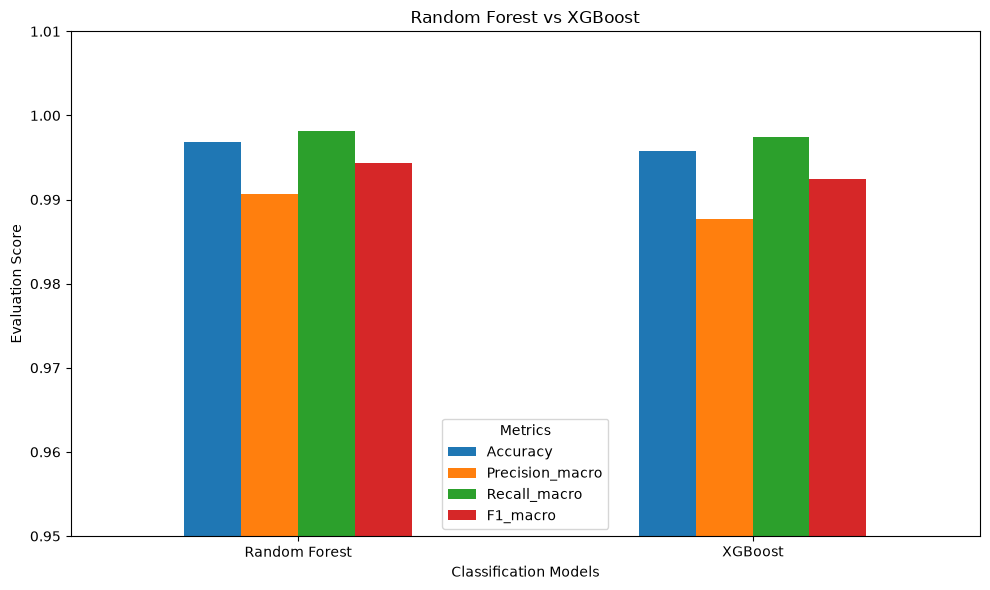


Comparison CSV saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\classification_model_comparison.csv
Comparison chart saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\visualizations\classification_model_comparison.png


In [38]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

results_dir = project_dir / "data" / "processed"
visual_dir = project_dir / "visualizations"

visual_dir.mkdir(exist_ok=True)

# Load evaluation results
rf_results = pd.read_csv(
    results_dir / "random_forest_evaluation.csv"
)

xgb_results = pd.read_csv(
    results_dir / "xgboost_evaluation.csv"
)

# Combine model results
comparison = pd.concat(
    [rf_results, xgb_results],
    ignore_index=True
)

# Save comparison
comparison_path = (
    results_dir / "classification_model_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print("CLASSIFICATION MODEL COMPARISON")
print(comparison.to_string(index=False))

# Create evaluation chart
metrics = [
    "Accuracy",
    "Precision_macro",
    "Recall_macro",
    "F1_macro"
]

comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0.95, 1.01)
)

plt.title("Random Forest vs XGBoost")
plt.ylabel("Evaluation Score")
plt.xlabel("Classification Models")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()

chart_path = (
    visual_dir / "classification_model_comparison.png"
)

plt.savefig(chart_path, dpi=300)
plt.show()

print("\nComparison CSV saved:", comparison_path)
print("Comparison chart saved:", chart_path)

In [39]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"

module4 = pd.read_csv(
    processed_dir / "module4_processed_dataset.csv"
)

classification = pd.read_csv(
    processed_dir / "module5_classification_dataset.csv"
)

print("MODULE 4 DATASET")
print("Shape:", module4.shape)
print("Columns:", module4.columns.tolist())

print("\nCLASSIFICATION DATASET")
print("Shape:", classification.shape)
print("Columns:", classification.columns.tolist())

MODULE 4 DATASET
Shape: (7312, 23)
Columns: ['route_id', 'route_short_name', 'city', 'numeric__scheduled_trip_count', 'numeric__stop_count', 'numeric__estimated_straight_line_route_km', 'numeric__operating_day_count', 'numeric__start_service_hour', 'numeric__end_service_hour', 'numeric__operates_monday', 'numeric__operates_tuesday', 'numeric__operates_wednesday', 'numeric__operates_thursday', 'numeric__operates_friday', 'numeric__operates_saturday', 'numeric__operates_sunday', 'categorical__route_type_1', 'categorical__route_type_3', 'categorical__city_ahmedabad', 'categorical__city_chennai', 'categorical__city_hyderabad', 'categorical__city_mumbai', 'categorical__city_pune']

CLASSIFICATION DATASET
Shape: (4721, 16)
Columns: ['scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'trips_with_distance', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday', 'operating_day_count', 's

In [40]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"

module4 = pd.read_csv(
    processed_dir / "module4_processed_dataset.csv"
)

route_features = pd.read_csv(
    processed_dir / "route_features.csv"
)

# Keep Chennai routes from Module 4
module4_chennai = module4[
    module4["city"] == "chennai"
].copy()

# Get original GTFS route_type labels
labels = route_features[
    ["city", "route_id", "route_type"]
].copy()

# Match the Module 4 records with their original labels
matched = module4_chennai.merge(
    labels,
    on=["city", "route_id"],
    how="inner"
)

print("MODULE 4 CHENNAI ROUTES:", len(module4_chennai))
print("MATCHED ROUTES:", len(matched))
print("\nROUTE TYPE DISTRIBUTION:")
print(matched["route_type"].value_counts())

print("\nMISSING LABELS:", matched["route_type"].isna().sum())
print(
    "\nDUPLICATE ROUTE IDs:",
    matched.duplicated(["city", "route_id"]).sum()
)

MODULE 4 CHENNAI ROUTES: 4721
MATCHED ROUTES: 4721

ROUTE TYPE DISTRIBUTION:
route_type
3    3934
1     787
Name: count, dtype: int64

MISSING LABELS: 0

DUPLICATE ROUTE IDs: 0


In [41]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"

# Load Module 4 data and original GTFS labels
module4 = pd.read_csv(
    processed_dir / "module4_processed_dataset.csv"
)

route_features = pd.read_csv(
    processed_dir / "route_features.csv"
)

# Select Chennai routes
module4_chennai = module4[
    module4["city"] == "chennai"
].copy()

# Retrieve genuine GTFS labels
labels = route_features[
    ["city", "route_id", "route_type"]
].copy()

# Merge features with original labels
classification_data = module4_chennai.merge(
    labels,
    on=["city", "route_id"],
    how="inner"
)

# Select only Module 4 numerical features
feature_columns = [
    col for col in classification_data.columns
    if col.startswith("numeric__")
]

# Keep identifiers, numerical features and target
final_columns = [
    "route_id",
    "route_short_name",
    "city"
] + feature_columns + ["route_type"]

classification_data = classification_data[
    final_columns
]

# Save as a new file without overwriting the old dataset
output_path = (
    processed_dir / "module5_classification_dataset_module4.csv"
)

classification_data.to_csv(output_path, index=False)

print("CORRECTED CLASSIFICATION DATASET CREATED!")
print("Shape:", classification_data.shape)
print("\nColumns:")
print(classification_data.columns.tolist())

print("\nTarget distribution:")
print(classification_data["route_type"].value_counts())

print("\nMissing values:", classification_data.isnull().sum().sum())
print("\nSaved:", output_path)

CORRECTED CLASSIFICATION DATASET CREATED!
Shape: (4721, 17)

Columns:
['route_id', 'route_short_name', 'city', 'numeric__scheduled_trip_count', 'numeric__stop_count', 'numeric__estimated_straight_line_route_km', 'numeric__operating_day_count', 'numeric__start_service_hour', 'numeric__end_service_hour', 'numeric__operates_monday', 'numeric__operates_tuesday', 'numeric__operates_wednesday', 'numeric__operates_thursday', 'numeric__operates_friday', 'numeric__operates_saturday', 'numeric__operates_sunday', 'route_type']

Target distribution:
route_type
3    3934
1     787
Name: count, dtype: int64

Missing values: 0

Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\module5_classification_dataset_module4.csv


In [42]:
from pathlib import Path
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"
models_dir = project_dir / "models"

models_dir.mkdir(exist_ok=True)

# Load corrected Module 4 classification dataset
df = pd.read_csv(
    processed_dir / "module5_classification_dataset_module4.csv"
)

# Select input features and target
feature_columns = [
    col for col in df.columns
    if col.startswith("numeric__")
]

X = df[feature_columns]
y = df["route_type"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
rf_predictions = rf_model.predict(X_test)

# Evaluation
accuracy = accuracy_score(y_test, rf_predictions)
precision = precision_score(
    y_test, rf_predictions, average="macro"
)
recall = recall_score(
    y_test, rf_predictions, average="macro"
)
f1 = f1_score(
    y_test, rf_predictions, average="macro"
)

print("\nRANDOM FOREST EVALUATION")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        labels=[1, 3],
        target_names=["Metro", "Bus"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions, labels=[1, 3]))

# Save model
joblib.dump(
    rf_model,
    models_dir / "random_forest_classifier_module4.pkl"
)

# Save evaluation metrics
rf_results = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": accuracy,
    "Precision_macro": precision,
    "Recall_macro": recall,
    "F1_macro": f1
}])

rf_results.to_csv(
    processed_dir / "random_forest_evaluation_module4.csv",
    index=False
)

print("\nRandom Forest model and evaluation saved successfully!")

Training shape: (3776, 13)
Testing shape: (945, 13)

RANDOM FOREST EVALUATION
Accuracy : 0.9958
Precision: 0.99
Recall   : 0.9949
F1-Score : 0.9924

Classification Report:
              precision    recall  f1-score   support

       Metro       0.98      0.99      0.99       158
         Bus       1.00      1.00      1.00       787

    accuracy                           1.00       945
   macro avg       0.99      0.99      0.99       945
weighted avg       1.00      1.00      1.00       945

Confusion Matrix:
[[157   1]
 [  3 784]]

Random Forest model and evaluation saved successfully!


In [43]:
from pathlib import Path
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"
models_dir = project_dir / "models"

# Load corrected dataset
df = pd.read_csv(
    processed_dir / "module5_classification_dataset_module4.csv"
)

# Select features and target
feature_columns = [
    col for col in df.columns
    if col.startswith("numeric__")
]

X = df[feature_columns]
y = df["route_type"]

# Encode Metro as 1 and Bus as 0
y_binary = (y == 1).astype(int)

# Same train/test split as Random Forest
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

# Handle class imbalance
scale_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

# Predict
predictions_binary = xgb_model.predict(X_test)

# Convert predictions back to original GTFS labels
y_test_original = y_test.map({1: 1, 0: 3})
predictions = pd.Series(predictions_binary).map(
    {1: 1, 0: 3}
)

# Evaluation
accuracy = accuracy_score(y_test_original, predictions)
precision = precision_score(
    y_test_original, predictions, average="macro"
)
recall = recall_score(
    y_test_original, predictions, average="macro"
)
f1 = f1_score(
    y_test_original, predictions, average="macro"
)

print("XGBOOST CLASSIFICATION RESULTS")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_original,
        predictions,
        labels=[1, 3],
        target_names=["Metro", "Bus"]
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_original,
        predictions,
        labels=[1, 3]
    )
)

# Save model
joblib.dump(
    xgb_model,
    models_dir / "xgboost_classifier_module4.pkl"
)

# Save evaluation
xgb_results = pd.DataFrame([{
    "Model": "XGBoost",
    "Accuracy": accuracy,
    "Precision_macro": precision,
    "Recall_macro": recall,
    "F1_macro": f1
}])

xgb_results.to_csv(
    processed_dir / "xgboost_evaluation_module4.csv",
    index=False
)

print("\nXGBoost model and evaluation saved successfully!")

XGBOOST CLASSIFICATION RESULTS
Accuracy : 0.9958
Precision: 0.9877
Recall   : 0.9975
F1-Score : 0.9925

Classification Report:
              precision    recall  f1-score   support

       Metro       0.98      1.00      0.99       158
         Bus       1.00      0.99      1.00       787

    accuracy                           1.00       945
   macro avg       0.99      1.00      0.99       945
weighted avg       1.00      1.00      1.00       945

Confusion Matrix:
[[158   0]
 [  4 783]]

XGBoost model and evaluation saved successfully!


FINAL CLASSIFICATION MODEL COMPARISON
        Model  Accuracy  Precision_macro  Recall_macro  F1_macro
Random Forest  0.995767         0.989988      0.994929  0.992438
      XGBoost  0.995767         0.987654      0.997459  0.992476


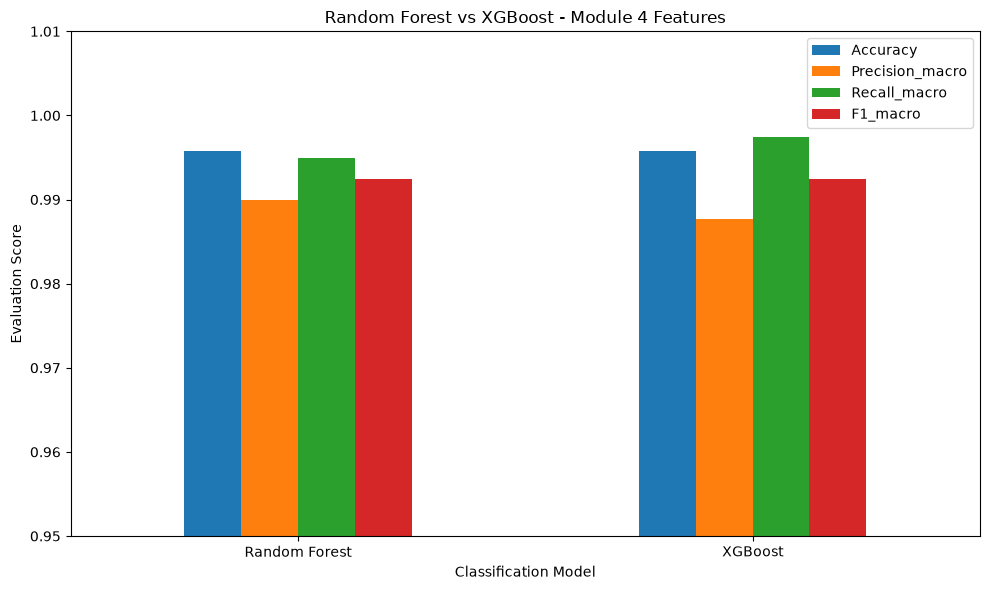


Comparison CSV and chart saved successfully!


In [44]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"
visual_dir = project_dir / "visualizations"

# Load corrected evaluation results
rf = pd.read_csv(
    processed_dir / "random_forest_evaluation_module4.csv"
)

xgb = pd.read_csv(
    processed_dir / "xgboost_evaluation_module4.csv"
)

# Compare both models
comparison = pd.concat([rf, xgb], ignore_index=True)

comparison.to_csv(
    processed_dir / "classification_model_comparison_module4.csv",
    index=False
)

print("FINAL CLASSIFICATION MODEL COMPARISON")
print(comparison.to_string(index=False))

# Plot comparison
metrics = [
    "Accuracy",
    "Precision_macro",
    "Recall_macro",
    "F1_macro"
]

comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0.95, 1.01)
)

plt.title("Random Forest vs XGBoost - Module 4 Features")
plt.ylabel("Evaluation Score")
plt.xlabel("Classification Model")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    visual_dir / "classification_model_comparison_module4.png",
    dpi=300
)

plt.show()

print("\nComparison CSV and chart saved successfully!")

In [45]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

report_path = (
    project_dir / "reports" / "module5_final_report.md"
)

if report_path.exists():
    report = report_path.read_text(encoding="utf-8")

    print("REPORT FOUND!")
    print("\nREPORT CONTENT:\n")
    print(report)
else:
    print("Report file not found:", report_path)

REPORT FOUND!

REPORT CONTENT:


# RouteRanker – Module 5: Machine Learning

## 1. Objective
Apply machine learning techniques to identify similar public transit
route patterns and detect unusual route records.

## 2. Dataset
- Total route records: 7,312
- Selected clustering features: 15
- Missing values: 0
- Infinite values: 0
- Cities: Ahmedabad, Chennai, Hyderabad, Mumbai, Pune

## 3. K-Means Clustering
K values tested: 2, 3, 4, 5.

Selected candidate: K = 4

- Silhouette Score: 0.865398
- Davies-Bouldin Index: 0.228795
- Inertia: 212.018324

Cluster distribution:
- Cluster 0: 6,525 routes
- Cluster 1: 180 routes
- Cluster 2: 227 routes
- Cluster 3: 380 routes

PCA explained variance:
- Component 1: 64.32%
- Component 2: 24.54%
- Combined: 88.86%

## 4. DBSCAN Clustering
Selected parameters:
- eps: 0.3
- min_samples: 10

Results:
- Number of clusters: 4
- Core points: 7,305
- Border points: 1
- Noise points: 6
- Silhouette Score: 0.864634
- Davies-Bouldin Index: 0.228631

Noise rou

In [46]:
from pathlib import Path

report_path = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md"
)

report = report_path.read_text(encoding="utf-8")

print("Report saved:", report_path.exists())
print("Contains Random Forest:", "Random Forest" in report)
print("Contains XGBoost:", "XGBoost" in report)
print("Contains classification comparison:", "Classification Model Comparison" in report)
print("Report length:", len(report), "characters")

Report saved: True
Contains Random Forest: True
Contains XGBoost: True
Contains classification comparison: False
Report length: 4318 characters


In [47]:
from pathlib import Path

report_path = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md"
)

report = report_path.read_text(encoding="utf-8")

for line_number, line in enumerate(report.splitlines(), start=1):
    if "comparison" in line.lower() or "6.3" in line:
        print(f"Line {line_number}: {line}")

Line 50: ## 5. Model Comparison


In [48]:
from pathlib import Path

report_path = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md"
)

report = report_path.read_text(encoding="utf-8")

new_section = """
### 6.3 Classification Model Comparison

| Metric | Random Forest | XGBoost |
|---|---:|---:|
| Accuracy | 99.5767% | 99.5767% |
| Macro Precision | 98.9988% | 98.7654% |
| Macro Recall | 99.4929% | 99.7459% |
| Macro F1-score | 99.2438% | 99.2476% |

Both models achieved the same accuracy.

- Random Forest achieved slightly higher precision.
- XGBoost achieved slightly higher recall and F1-score.
- Neither model was clearly superior across every evaluation metric.

The comparison was performed using the same corrected Module 4
features and the same training and testing split.
"""

if "### 6.3 Classification Model Comparison" not in report:
    report = report.replace(
        "## 7. Limitations",
        new_section + "\n## 7. Limitations"
    )

    report_path.write_text(report, encoding="utf-8")
    print("Classification comparison section added!")
else:
    print("Classification comparison section already exists.")

print("Report updated successfully!")

Classification comparison section added!
Report updated successfully!


In [49]:
from pathlib import Path

report_path = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md"
)

report = report_path.read_text(encoding="utf-8")

print("CLASSIFICATION-RELATED REPORT LINES")
print("-" * 45)

for line in report.splitlines():
    if any(word in line.lower() for word in [
        "random", "xgboost", "supervised", "classification"
    ]):
        print(repr(line))

CLASSIFICATION-RELATED REPORT LINES
---------------------------------------------
'## 6. Supervised Learning'
'Therefore, Random Forest and XGBoost classification'
'### 6.3 Classification Model Comparison'
'| Metric | Random Forest | XGBoost |'
'- Random Forest achieved slightly higher precision.'
'- XGBoost achieved slightly higher recall and F1-score.'


In [50]:
from pathlib import Path
import re

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

report_path = project_dir / "reports" / "module5_final_report.md"

report = report_path.read_text(encoding="utf-8")

new_section = """
## 6. Supervised Classification

Supervised classification was performed using the genuine GTFS
route_type field as the target variable.

The classification task was to distinguish between:
- Metro: route_type 1
- Bus: route_type 3

The corrected dataset used 13 numerical features from Module 4.
Route identifiers, city columns and encoded route-type columns
were excluded from the model inputs.

Dataset details:
- Total Chennai routes: 4,721
- Training records: 3,776
- Testing records: 945
- Missing values: 0
- Train/test split: 80:20
- Random state: 42

### 6.1 Random Forest Classification

Model configuration:
- Estimators: 300
- Class weighting: Balanced
- Random state: 42

Evaluation results:
- Accuracy: 99.5767%
- Macro Precision: 98.9988%
- Macro Recall: 99.4929%
- Macro F1-score: 99.2438%

Confusion Matrix:

| | Predicted Metro | Predicted Bus |
|---|---:|---:|
| Actual Metro | 157 | 1 |
| Actual Bus | 3 | 784 |

### 6.2 XGBoost Classification

Model configuration:
- Estimators: 300
- Maximum depth: 5
- Learning rate: 0.05
- Evaluation metric: Log Loss
- Random state: 42

Evaluation results:
- Accuracy: 99.5767%
- Macro Precision: 98.7654%
- Macro Recall: 99.7459%
- Macro F1-score: 99.2476%

Confusion Matrix:

| | Predicted Metro | Predicted Bus |
|---|---:|---:|
| Actual Metro | 158 | 0 |
| Actual Bus | 4 | 783 |

### 6.3 Classification Model Comparison

| Metric | Random Forest | XGBoost |
|---|---:|---:|
| Accuracy | 99.5767% | 99.5767% |
| Macro Precision | 98.9988% | 98.7654% |
| Macro Recall | 99.4929% | 99.7459% |
| Macro F1-score | 99.2438% | 99.2476% |

Both models achieved the same accuracy.
Random Forest achieved slightly higher precision,
while XGBoost achieved slightly higher recall and F1-score.

Neither model was clearly superior across every metric.

**Classification limitation:** The experiment used Chennai routes only.
The models predict transport mode, not passenger demand,
overcrowding or route efficiency. Their results should not be
assumed to generalize to the other four cities.
"""

pattern = r"## 6\..*?(?=## 7\.)"

updated_report, count = re.subn(
    pattern,
    new_section.strip() + "\n\n",
    report,
    count=1,
    flags=re.DOTALL
)

if count == 1:
    report_path.write_text(updated_report, encoding="utf-8")
    print("Section 6 successfully updated!")
else:
    print("Section 6 was not replaced. Please check the report headings.")

print("Report saved:", report_path.exists())

Section 6 successfully updated!
Report saved: True


In [51]:
from pathlib import Path

report_path = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module5_final_report.md"
)

report = report_path.read_text(encoding="utf-8")

checks = {
    "K-Means section": "K-Means Clustering" in report,
    "DBSCAN section": "DBSCAN Clustering" in report,
    "Random Forest Classification": "### 6.1 Random Forest Classification" in report,
    "XGBoost Classification": "### 6.2 XGBoost Classification" in report,
    "Classification Comparison": "### 6.3 Classification Model Comparison" in report,
    "Old incorrect statement removed": "classification were not performed" not in report,
    "Limitations": "Limitations" in report,
    "Route Optimization Suggestions": "Route Optimization Suggestions" in report
}

for name, result in checks.items():
    print(f"{name}: {'PASS' if result else 'CHECK'}")

print("\nALL CHECKS PASSED:", all(checks.values()))

K-Means section: PASS
DBSCAN section: PASS
Random Forest Classification: PASS
XGBoost Classification: PASS
Classification Comparison: PASS
Old incorrect statement removed: PASS
Limitations: PASS
Route Optimization Suggestions: PASS

ALL CHECKS PASSED: True


In [52]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

required_files = [
    "data/processed/module5_clustering_features.csv",
    "data/processed/kmeans_experiment_results.csv",
    "data/processed/kmeans_evaluation_results.csv",
    "data/processed/kmeans_route_clusters.csv",
    "data/processed/dbscan_parameter_results.csv",
    "data/processed/dbscan_cluster_labels.csv",
    "data/processed/dbscan_noise_routes.csv",
    "data/processed/dbscan_point_types.csv",
    "data/processed/module5_classification_dataset_module4.csv",
    "data/processed/random_forest_evaluation_module4.csv",
    "data/processed/xgboost_evaluation_module4.csv",
    "data/processed/classification_model_comparison_module4.csv",
    "models/kmeans_final_model.pkl",
    "models/dbscan_final_model.pkl",
    "models/random_forest_classifier_module4.pkl",
    "models/xgboost_classifier_module4.pkl",
    "visualizations/elbow_method.png",
    "visualizations/kmeans_cluster_visualization.png",
    "visualizations/dbscan_cluster_visualization.png",
    "visualizations/classification_model_comparison_module4.png",
    "reports/module5_final_report.md"
]

missing_files = []

for file in required_files:
    path = project_dir / file

    if path.exists():
        print(f"PASS: {file}")
    else:
        print(f"MISSING: {file}")
        missing_files.append(file)

print("\nTotal files checked:", len(required_files))
print("Files found:", len(required_files) - len(missing_files))
print("Files missing:", len(missing_files))

if not missing_files:
    print("\nALL REQUIRED FILES FOUND! 🎉")

PASS: data/processed/module5_clustering_features.csv
PASS: data/processed/kmeans_experiment_results.csv
PASS: data/processed/kmeans_evaluation_results.csv
PASS: data/processed/kmeans_route_clusters.csv
PASS: data/processed/dbscan_parameter_results.csv
PASS: data/processed/dbscan_cluster_labels.csv
PASS: data/processed/dbscan_noise_routes.csv
PASS: data/processed/dbscan_point_types.csv
PASS: data/processed/module5_classification_dataset_module4.csv
PASS: data/processed/random_forest_evaluation_module4.csv
PASS: data/processed/xgboost_evaluation_module4.csv
PASS: data/processed/classification_model_comparison_module4.csv
PASS: models/kmeans_final_model.pkl
PASS: models/dbscan_final_model.pkl
PASS: models/random_forest_classifier_module4.pkl
PASS: models/xgboost_classifier_module4.pkl
PASS: visualizations/elbow_method.png
PASS: visualizations/kmeans_cluster_visualization.png
PASS: visualizations/dbscan_cluster_visualization.png
PASS: visualizations/classification_model_comparison_module4.

In [53]:
from pathlib import Path

src_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src"
)

required_scripts = [
    "kmeans_clustering.py",
    "dbscan_clustering.py",
    "random_forest_classification.py",
    "xgboost_classification.py"
]

for filename in required_scripts:
    path = src_dir / filename

    if path.exists():
        print(f"PASS: {filename}")
    else:
        print(f"MISSING: {filename}")

PASS: kmeans_clustering.py
PASS: dbscan_clustering.py
PASS: random_forest_classification.py
PASS: xgboost_classification.py


In [54]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

src_dir = project_dir / "src"
src_dir.mkdir(parents=True, exist_ok=True)

# -------------------------------
# 1. Random Forest script
# -------------------------------

rf_code = r'''
from pathlib import Path
import joblib
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

PROJECT_DIR = Path(__file__).resolve().parents[1]
DATA_PATH = PROJECT_DIR / "data" / "processed" / "module5_classification_dataset_module4.csv"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

feature_columns = [
    column for column in df.columns
    if column.startswith("numeric__")
]

X = df[feature_columns]
y = df["route_type"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(
    y_test, predictions, labels=[1, 3],
    average="macro", zero_division=0
)
recall = recall_score(
    y_test, predictions, labels=[1, 3],
    average="macro", zero_division=0
)
f1 = f1_score(
    y_test, predictions, labels=[1, 3],
    average="macro", zero_division=0
)

results = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": accuracy,
    "Precision_macro": precision,
    "Recall_macro": recall,
    "F1_macro": f1
}])

results.to_csv(
    OUTPUT_DIR / "random_forest_evaluation_module4.csv",
    index=False
)

joblib.dump(
    model,
    MODEL_DIR / "random_forest_classifier_module4.pkl"
)

print("Random Forest training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Features used:", len(feature_columns))
print("\nEvaluation results:")
print(results.to_string(index=False))
print("\nConfusion Matrix (labels: Metro=1, Bus=3):")
print(confusion_matrix(y_test, predictions, labels=[1, 3]))
print("\nClassification Report:")
print(classification_report(
    y_test, predictions, labels=[1, 3],
    target_names=["Metro", "Bus"], zero_division=0
))
print("\nModel saved successfully.")
'''

rf_path = src_dir / "random_forest_classification.py"
rf_path.write_text(rf_code.strip() + "\n", encoding="utf-8")


# -------------------------------
# 2. XGBoost script
# -------------------------------

xgb_code = r'''
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from xgboost import XGBClassifier

PROJECT_DIR = Path(__file__).resolve().parents[1]
DATA_PATH = PROJECT_DIR / "data" / "processed" / "module5_classification_dataset_module4.csv"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

feature_columns = [
    column for column in df.columns
    if column.startswith("numeric__")
]

X = df[feature_columns]
y = df["route_type"].astype(int)

# Metro = 1; Bus = 3.
# XGBoost uses binary labels: Metro = 1; Bus = 0.
y_binary = (y == 1).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

metro_count = int((y_train == 1).sum())
bus_count = int((y_train == 0).sum())
scale_pos_weight = bus_count / metro_count

model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions_binary = model.predict(X_test)

# Convert predictions back to the original GTFS route_type labels.
y_test_original = np.where(y_test == 1, 1, 3)
predictions = np.where(predictions_binary == 1, 1, 3)

accuracy = accuracy_score(y_test_original, predictions)
precision = precision_score(
    y_test_original, predictions, labels=[1, 3],
    average="macro", zero_division=0
)
recall = recall_score(
    y_test_original, predictions, labels=[1, 3],
    average="macro", zero_division=0
)
f1 = f1_score(
    y_test_original, predictions, labels=[1, 3],
    average="macro", zero_division=0
)

results = pd.DataFrame([{
    "Model": "XGBoost",
    "Accuracy": accuracy,
    "Precision_macro": precision,
    "Recall_macro": recall,
    "F1_macro": f1
}])

results.to_csv(
    OUTPUT_DIR / "xgboost_evaluation_module4.csv",
    index=False
)

joblib.dump(
    model,
    MODEL_DIR / "xgboost_classifier_module4.pkl"
)

print("XGBoost training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Features used:", len(feature_columns))
print("\nEvaluation results:")
print(results.to_string(index=False))
print("\nConfusion Matrix (labels: Metro=1, Bus=3):")
print(confusion_matrix(
    y_test_original, predictions, labels=[1, 3]
))
print("\nClassification Report:")
print(classification_report(
    y_test_original, predictions, labels=[1, 3],
    target_names=["Metro", "Bus"], zero_division=0
))
print("\nModel saved successfully.")
'''

xgb_path = src_dir / "xgboost_classification.py"
xgb_path.write_text(xgb_code.strip() + "\n", encoding="utf-8")

print("Created:", rf_path.name)
print("Created:", xgb_path.name)
print("Both scripts saved in:", src_dir)

Created: random_forest_classification.py
Created: xgboost_classification.py
Both scripts saved in: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src


In [55]:
from pathlib import Path

src_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\src"
)

scripts = [
    "kmeans_clustering.py",
    "dbscan_clustering.py",
    "random_forest_classification.py",
    "xgboost_classification.py"
]

for filename in scripts:
    path = src_dir / filename

    status = (
        "PASS"
        if path.exists() and path.stat().st_size > 0
        else "MISSING"
    )

    print(f"{filename}: {status}")

print("\nAll four scripts present:",
      all((src_dir / name).exists() for name in scripts))

kmeans_clustering.py: PASS
dbscan_clustering.py: PASS
random_forest_classification.py: PASS
xgboost_classification.py: PASS

All four scripts present: True


In [56]:
import subprocess
import sys

rf_script = src_dir / "random_forest_classification.py"

result = subprocess.run(
    [sys.executable, str(rf_script)],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr)
else:
    print("Random Forest script executed successfully! 🎉")

Random Forest training completed!
Training records: 3776
Testing records: 945
Features used: 13

Evaluation results:
        Model  Accuracy  Precision_macro  Recall_macro  F1_macro
Random Forest  0.995767         0.989988      0.994929  0.992438

Confusion Matrix (labels: Metro=1, Bus=3):
[[157   1]
 [  3 784]]

Classification Report:
              precision    recall  f1-score   support

       Metro       0.98      0.99      0.99       158
         Bus       1.00      1.00      1.00       787

    accuracy                           1.00       945
   macro avg       0.99      0.99      0.99       945
weighted avg       1.00      1.00      1.00       945


Model saved successfully.

Random Forest script executed successfully! 🎉


In [57]:
xgb_script = src_dir / "xgboost_classification.py"

result = subprocess.run(
    [sys.executable, str(xgb_script)],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr)
else:
    print("XGBoost script executed successfully! 🎉")

XGBoost training completed!
Training records: 3776
Testing records: 945
Features used: 13

Evaluation results:
  Model  Accuracy  Precision_macro  Recall_macro  F1_macro
XGBoost  0.995767         0.987654      0.997459  0.992476

Confusion Matrix (labels: Metro=1, Bus=3):
[[158   0]
 [  4 783]]

Classification Report:
              precision    recall  f1-score   support

       Metro       0.98      1.00      0.99       158
         Bus       1.00      0.99      1.00       787

    accuracy                           1.00       945
   macro avg       0.99      1.00      0.99       945
weighted avg       1.00      1.00      1.00       945


Model saved successfully.

XGBoost script executed successfully! 🎉


In [58]:
import pandas as pd
import joblib
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

# Load clustering features
X = pd.read_csv(
    project_dir / "data/processed/module5_clustering_features.csv"
)

# Load final K-Means model
kmeans = joblib.load(
    project_dir / "models/kmeans_final_model.pkl"
)

# 1. Number of clusters
print("Number of clusters:", kmeans.n_clusters)

# 2. Number of iterations
print("Number of iterations:", kmeans.n_iter_)

# 3. Centroid values
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X.columns
)

print("\nCENTROID VALUES:")
display(centroids)

# 4. Distance from each route to every centroid
distances = kmeans.transform(X)

distance_df = pd.DataFrame(
    distances,
    columns=[
        f"Distance_to_Cluster_{i}"
        for i in range(kmeans.n_clusters)
    ]
)

print("\nDISTANCES FOR FIRST 5 ROUTES:")
display(distance_df.head())

print("\nVerification completed!")

Number of clusters: 4
Number of iterations: 2

CENTROID VALUES:


,numeric__scheduled_trip_count,numeric__stop_count,numeric__estimated_straight_line_route_km,numeric__operating_day_count,numeric__start_service_hour,numeric__end_service_hour,numeric__operates_monday,numeric__operates_tuesday,numeric__operates_wednesday,numeric__operates_thursday,numeric__operates_friday,numeric__operates_saturday,numeric__operates_sunday,categorical__route_type_1,categorical__route_type_3
0,1.535102e-02,0.045638,0.026641,9.999234e-01,0.229268,0.070833,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,9.995402e-01,3.774758e-15,1.000000e+00
1,4.163336e-17,0.027617,0.063795,2.331468e-15,0.397222,0.044802,2.220446e-15,2.220446e-15,2.220446e-15,2.220446e-15,2.220446e-15,2.220446e-15,1.000000e+00,1.000000e+00,-3.552714e-15
2,1.260765e-03,0.026343,0.060963,8.333333e-01,0.357346,0.042906,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.551115e-16,1.000000e+00,-4.107825e-15
3,1.370432e-16,0.023187,0.055300,1.000000e+00,0.372214,0.043950,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-4.996004e-15



DISTANCES FOR FIRST 5 ROUTES:


,Distance_to_Cluster_0,Distance_to_Cluster_1,Distance_to_Cluster_2,Distance_to_Cluster_3
0,0.065901,3.008276,1.749745,1.428158
1,0.075819,3.009248,1.751403,1.430166
2,0.085033,3.011089,1.753862,1.433355
3,0.125692,3.000885,1.740971,1.415289
4,0.135533,3.012500,1.756313,1.436673



Verification completed!


In [59]:
from pathlib import Path

evidence_path = (
    project_dir / "reports" / "kmeans_technical_evidence.md"
)

evidence = """# K-Means Technical Evidence

- Selected number of clusters: 4
- Number of iterations: 2
- Number of features: 15
- Centroids: 4 generated.
- Distance calculation: Distance from every route to all 4 centroids.
- Cluster assignment: Based on minimum centroid distance.

The final K-Means model was loaded from the saved model file.
No model retraining was performed for this verification.
"""

evidence_path.write_text(evidence, encoding="utf-8")

print("K-Means evidence saved successfully!")
print(evidence_path)

K-Means evidence saved successfully!
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\kmeans_technical_evidence.md


In [60]:
result = subprocess.run(
    ["git", "add", "-f", "--",
     "reports/kmeans_technical_evidence.md"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("K-Means evidence staged successfully!")
else:
    print(result.stderr)

K-Means evidence staged successfully!


In [61]:
result = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print(result.stdout)


 M models/dbscan_final_model.pkl
 M models/kmeans_final_model.pkl
 M models/kmeans_model_k2.pkl
 M models/kmeans_model_k3.pkl
 M models/kmeans_model_k4.pkl
 M models/kmeans_model_k5.pkl
 M models/random_forest_classifier_module4.pkl
 M models/xgboost_classifier_module4.pkl
 M notebook/module5_machine_learning.ipynb
?? models/random_forest_classifier.pkl
?? models/xgboost_classifier.pkl
?? notebook/.ipynb_checkpoints/
?? notebook/data/
?? visualizations/classification_model_comparison.png



In [62]:
module5_files = [
    "notebook/module5_machine_learning.ipynb",

    "reports/module5_final_report.md",
    "reports/kmeans_technical_evidence.md",

    "src/kmeans_clustering.py",
    "src/dbscan_clustering.py",
    "src/random_forest_classification.py",
    "src/xgboost_classification.py",

    "models/kmeans_model_k2.pkl",
    "models/kmeans_model_k3.pkl",
    "models/kmeans_model_k4.pkl",
    "models/kmeans_model_k5.pkl",
    "models/kmeans_final_model.pkl",
    "models/dbscan_final_model.pkl",
    "models/random_forest_classifier_module4.pkl",
    "models/xgboost_classifier_module4.pkl",

    "data/processed/module5_clustering_features.csv",
    "data/processed/kmeans_experiment_results.csv",
    "data/processed/kmeans_evaluation_results.csv",
    "data/processed/kmeans_route_clusters.csv",
    "data/processed/dbscan_parameter_results.csv",
    "data/processed/dbscan_cluster_labels.csv",
    "data/processed/dbscan_noise_routes.csv",
    "data/processed/dbscan_point_types.csv",
    "data/processed/module5_classification_dataset_module4.csv",
    "data/processed/random_forest_evaluation_module4.csv",
    "data/processed/xgboost_evaluation_module4.csv",
    "data/processed/classification_model_comparison_module4.csv",

    "visualizations/elbow_method.png",
    "visualizations/kmeans_cluster_visualization.png",
    "visualizations/dbscan_cluster_visualization.png",
    "visualizations/classification_model_comparison_module4.png"
]

result = subprocess.run(
    ["git", "add", "-f", "--"] + module5_files,
    cwd=project_dir,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0




In [63]:
result = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print(result.stdout)


M  models/dbscan_final_model.pkl
M  models/kmeans_final_model.pkl
M  models/kmeans_model_k2.pkl
M  models/kmeans_model_k3.pkl
M  models/kmeans_model_k4.pkl
M  models/kmeans_model_k5.pkl
M  models/random_forest_classifier_module4.pkl
M  models/xgboost_classifier_module4.pkl
M  notebook/module5_machine_learning.ipynb
?? models/random_forest_classifier.pkl
?? models/xgboost_classifier.pkl
?? notebook/.ipynb_checkpoints/
?? notebook/data/
?? visualizations/classification_model_comparison.png

